# Background

- **Author**: 待學生確認（本次對話者與分工尚未確認）
- **Created At**: 2026-11-09
- **Research Motivation and Context (why are we interested in the findings?)：** 依使用者指定，收入高州群為 MA、CO、DC，收入低州群為 NM、LA、MS；各群合併申請筆數後，比較四個收入組內白人、亞洲人與黑人的房貸核准率。使用 [高收入州群申請](../data/processed/state_MA-CO-DC_income_high_15_columns.csv)、[低收入州群申請](../data/processed/state_NM-LA-MS_income_low_15_columns.csv) 與 [2024 ACS 州群家戶收入門檻](../data/processed/income_quartiles_by_income_group_2024.csv)。本文件的讀取驗證與樣本說明同時記錄輸入檢查。門檻由 [calculate_income_quartiles_by_income_group.py](../data/code/calculate_income_quartiles_by_income_group.py) 計算；房貸檔的上游產生程式與資料年份未確認。州群排名依使用者指定，本次未重新驗證各州收入排名。
- **Main Findings and Takeaways：** 來源 470,123 筆，排除無效收入 14,977 筆，納入 455,146 筆。Q2–Q4 三種族的高收入州群核准率均高於低收入州群。Q1 亞洲人在低收入州群較高（46.4% 對 41.5%），白人與黑人則以高收入州群較高。各群白人與亞洲人核准率均由 Q1 至 Q4 上升；高收入組黑人由 Q3 的 72.1% 小幅降至 Q4 的 71.0%。已從乾淨 Jupyter kernel 完整執行；24 組結果表重新讀取核對，四張圖與總覽圖已檢閱。不同州群的收入界線不同，結果僅屬描述性比較。
- **Future Direction：** 確認房貸資料年份，並進一步納入州別、信用、貸款條件與機構差異；本次僅描述關聯。


In [1]:
# Load packages
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib import font_manager
from IPython.display import Markdown
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = next((f for f in ['Heiti TC', 'Arial Unicode MS', 'Noto Sans CJK TC'] if f in available_fonts), 'DejaVu Sans')
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.size'] = 11


In [2]:
from pathlib import Path
import hashlib
import pandas as pd
from IPython.display import display

start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (start, *start.parents) if (p/'AGENTS.md').is_file() and (p/'templates').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('請從 econ-5166-student-kit 或其子目錄執行。')
INPUTS = {
 'state_MA-CO-DC_income_high_15_columns.csv': 'bd7902271c1d3efa36bdd0d19d2f456753f4117db9a55fab9f434709ac904c8b',
 'state_NM-LA-MS_income_low_15_columns.csv': 'e8ff73e6c26ce0189345feed4972863f3f91696249bc4a7c8fed37b0a0ccc7a4',
 'income_quartiles_by_income_group_2024.csv': '71e82046bd121e36ea947fd2c32c80843c787819471000f51ec1f6145cd33e1f',
}
def read_verified(name):
    path=(PROJECT_ROOT/'data/processed'/name).resolve()
    assert path.is_relative_to((PROJECT_ROOT/'data/processed').resolve())
    if hashlib.sha256(path.read_bytes()).hexdigest()!=INPUTS[name]:
        raise ValueError(f'資料版本變更，請先核對：{name}')
    return pd.read_csv(path)
groups=['High','Low']
states=[{'MA','CO','DC'},{'NM','LA','MS'}]
races=['White','Asian','Black or African American']
parts=[]
for name,group,expected_states,expected_n in zip(list(INPUTS)[:2],groups,states,[287517,182606]):
    frame=read_verified(name)
    assert frame.shape==(expected_n,15)
    assert {'state_code','derived_race','income','action_taken'}<=set(frame)
    assert set(frame.state_code)==expected_states
    assert set(frame.derived_race)==set(races)
    assert set(frame.action_taken)=={1,2,3}
    frame['state_group']=group
    parts.append(frame)
df=pd.concat(parts,ignore_index=True)
display(df.head(10))
quartile_source=read_verified('income_quartiles_by_income_group_2024.csv')
assert len(quartile_source)==2 and quartile_source.income_group.is_unique
assert set(quartile_source.income_group)==set(groups)
assert quartile_source[['Q1','Median','Q3']].notna().all().all()
assert (quartile_source.Q1<quartile_source.Median).all() and (quartile_source.Median<quartile_source.Q3).all()
for group,expected in zip(groups,[{'Massachusetts','Colorado','District of Columbia'},{'New Mexico','Louisiana','Mississippi'}]):
    actual=quartile_source.set_index('income_group').loc[group,'included_states']
    assert {s.strip() for s in actual.split(';')}==expected
display(quartile_source)
# income_group 在這份門檻檔代表州群，並不是申請人種族。
cutoffs=quartile_source.set_index('income_group')[['Q1','Median','Q3']].reindex(groups).rename(columns={'Q1':'P25','Median':'P50','Q3':'P75'})/1000
cutoffs.index.name='state_group'
income_numeric=pd.to_numeric(df.income,errors='coerce')
finite=income_numeric.notna() & np.isfinite(income_numeric)
analysis=df.loc[finite].copy()
analysis['income']=income_numeric.loc[analysis.index]
analysis['approved']=analysis.action_taken.isin([1,2]).astype(int)
analysis['income_quartile']=pd.Series(index=analysis.index,dtype='string')
for group in groups:
    mask=analysis.state_group.eq(group)
    analysis.loc[mask,'income_quartile']=pd.cut(analysis.loc[mask,'income'],[-np.inf,*cutoffs.loc[group],np.inf],labels=['Q1','Q2','Q3','Q4'],right=True).astype('string')
assert analysis.income_quartile.notna().all()


,state_code,county_code,derived_ethnicity,derived_race,derived_sex,action_taken,loan_type,loan_purpose,loan_amount,loan_to_value_ratio,property_value,occupancy_type,income,debt_to_income_ratio,applicant_age,state_group
0,MA,25023.0,Not Hispanic or Latino,Black or African American,Male,1,1,1,605000.0,95.00000,635000,1,147.0,45,25-34,High
1,CO,8041.0,Not Hispanic or Latino,White,Male,1,3,31,535000.0,NaN,NaN,1,NaN,NaN,35-44,High
2,MA,25021.0,Not Hispanic or Latino,Black or African American,Female,3,2,32,245000.0,77.42000,315000,1,73.0,>60%,35-44,High
3,MA,25027.0,Not Hispanic or Latino,White,Joint,1,3,31,395000.0,NaN,NaN,1,NaN,NaN,25-34,High
4,MA,25023.0,Not Hispanic or Latino,White,Joint,2,2,31,485000.0,NaN,NaN,1,NaN,NaN,45-54,High
5,CO,8015.0,Not Hispanic or Latino,White,Joint,1,3,31,515000.0,NaN,NaN,1,NaN,NaN,25-34,High
6,CO,8055.0,Not Hispanic or Latino,White,Female,1,1,32,195000.0,NaN,NaN,1,42.0,43,65-74,High
7,MA,25017.0,Not Hispanic or Latino,White,Joint,1,3,32,865000.0,86.50000,1005000,1,382.0,50%-60%,35-44,High
8,CO,8001.0,Not Hispanic or Latino,White,Female,1,2,32,465000.0,79.45000,575000,1,95.0,50%-60%,25-34,High
9,CO,8059.0,Not Hispanic or Latino,White,Male,1,1,31,315000.0,NaN,NaN,1,108.0,30%-<36%,55-64,High


,income_group,included_states,sample_size_before_cleaning,sample_size_after_cleaning,estimated_households,Q1,Median,Q3,IQR
0,High,Massachusetts; Colorado; District of Columbia,70739,57575,5639384,50762.50,101525,178582.475,127819.975
1,Low,New Mexico; Louisiana; Mississippi,49821,39893,3882636,29442.25,60915,111677.500,82235.250


收入以千美元記錄，ACS 門檻以美元記錄；將門檻除以 1,000 後分組。每個州群的三種族共用該州群門檻。Q1：收入 ≤ P25；Q2：P25 < 收入 ≤ P50；Q3：P50 < 收入 ≤ P75；Q4：收入 > P75。保留有效負收入；只排除收入缺失或非有限值，不去除可能代表不同申請的相同列。

核准為 `action_taken` 1、2，拒絕為 3；核准率＝核准筆數／（核准＋拒絕筆數），不等同實際撥款率。輸入只有這三種結果及指定三種族。州群門檻來自一般家戶，不是房貸申請收入本身的分位數，因此各收入組的申請數不必各占 25%。


In [3]:
# Summary statistics for every variable used, before formal analysis
print(f'表 1：來源樣本 N={len(df):,}，有效收入 N={len(analysis):,}；收入單位：千美元')
display(income_numeric[finite].describe().to_frame('來源年收入'))
print('收入缺失或非有限值：',int((~finite).sum()))
display(pd.crosstab(df.state_group,finite).rename(columns={False:'收入無效／排除',True:'收入有效／納入'}))
for col in ['state_code','state_group','derived_race','action_taken']:
    counts=df[col].value_counts(dropna=True)
    print(f'表 2：來源 {col}，有效 N={counts.sum():,}，缺失 N={df[col].isna().sum():,}；比例分母為非缺失筆數')
    display(pd.DataFrame({'筆數':counts,'比例 (%)':counts/counts.sum()*100}))
print('表 3：兩州群 ACS 門檻摘要（美元），每群一列；Q1、Median、Q3 無缺失')
display(quartile_source[['Q1','Median','Q3']].describe().T)
print('included_states／income_group：兩群各一列、各占 50%；無缺失；僅作門檻對應，不代表申請人種族。')
print('表 4：分析樣本數值摘要（count 為有效 N；下列皆無缺失）')
display(analysis[['income','approved']].describe().T)
for col in ['state_code','state_group','derived_race','action_taken','income_quartile']:
    counts=analysis[col].value_counts(dropna=True)
    print(f'分析樣本 {col}：有效 N={counts.sum():,}；缺失 N={analysis[col].isna().sum():,}；比例分母為非缺失筆數')
    display(pd.DataFrame({'筆數':counts,'比例 (%)':counts/counts.sum()*100}))
print('圖表中的 n 是各州群／收入組／種族的有效申請數；沒有使用家戶權重或平均各州比率。')


表 1：來源樣本 N=470,123，有效收入 N=455,146；收入單位：千美元


,來源年收入
count,4.551460e+05
mean,2.629203e+02
std,3.794054e+04
min,-3.224000e+03
25%,6.900000e+01
50%,1.080000e+02
75%,1.710000e+02
max,1.739983e+07


收入缺失或非有限值： 14977


income,收入無效／排除,收入有效／納入
state_group,,
High,8404,279113
Low,6573,176033


表 2：來源 state_code，有效 N=470,123，缺失 N=0；比例分母為非缺失筆數


,筆數,比例 (%)
state_code,,
CO,151270,32.176686
MA,127860,27.197138
LA,79148,16.835594
MS,65543,13.941671
NM,37915,8.064911
DC,8387,1.784001


... (17 outputs left out)

,筆數,比例 (%)
action_taken,,
1,326783,71.797401
3,110124,24.195313
2,18239,4.007286


分析樣本 income_quartile：有效 N=455,146；缺失 N=0；比例分母為非缺失筆數


,筆數,比例 (%)
income_quartile,,
Q3,161284,35.435662
Q4,138863,30.509551
Q2,120918,26.56686
Q1,34081,7.487927


圖表中的 n 是各州群／收入組／種族的有效申請數；沒有使用家戶權重或平均各州比率。


### The actual analysis starts below

比較兩州群各收入組中的三種族核准率。使用 Wilson 95% 二項信賴區間；假定申請紀錄互相獨立，未調整同機構或重複申請相關性。


以下結果先合併同州群內的申請筆數，再按核准與拒絕計算；並非三州核准率的等權平均。兩群使用不同收入界線，Q1–Q4 表示相對於各州群家戶收入的位置，並非完全相同的美元收入。


In [4]:
# Wilson 95% intervals: descriptive binomial intervals, no lender clustering
idx = pd.MultiIndex.from_product([['Q1','Q2','Q3','Q4'],groups,races],names=['income_quartile','state_group','derived_race'])
summary = analysis.groupby(['income_quartile','state_group','derived_race']).agg(approved_n=('approved','sum'),n=('approved','size')).reindex(idx)
summary[['approved_n','n']] = summary[['approved_n','n']].fillna(0).astype(int)
summary['denied_n'] = summary.n-summary.approved_n
summary['approval_rate'] = summary.approved_n / summary.n.replace(0,np.nan)
z=1.959963984540054
n=summary.n.replace(0,np.nan)
p=summary.approval_rate
den=1+z*z/n
center=(p+z*z/(2*n))/den
half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
summary['ci95_low']=(center-half).clip(0,1)
summary['ci95_high']=(center+half).clip(0,1)
assert summary.n.sum()==len(analysis)
assert summary.approved_n.sum()==analysis.approved.sum()
valid = summary.n.gt(0)
assert summary.loc[valid,'approval_rate'].between(0,1).all()
assert (summary.loc[valid,'ci95_low'] <= summary.loc[valid,'approval_rate']+1e-12).all()
assert (summary.loc[valid,'ci95_high'] >= summary.loc[valid,'approval_rate']-1e-12).all()
print(f'表 6：各收入組、州群、種族的核准筆數、總筆數、核准率與 95% 信賴區間（總 N={len(analysis):,}）')
display(summary)
assets=PROJECT_ROOT/'finding/assets/income_groups_mortgage_approval'
assets.mkdir(parents=True,exist_ok=True)
summary.to_csv(assets/'approval_rates.csv')
cutoffs.to_csv(assets/'income_quartile_thresholds.csv')
# Reopen serialized result tables and verify their counts and values.
saved=pd.read_csv(assets/'approval_rates.csv')
assert len(saved)==24 and saved.n.sum()==len(analysis)
assert np.allclose(saved.approval_rate, summary.approval_rate, equal_nan=True)
assert np.allclose(pd.read_csv(assets/'income_quartile_thresholds.csv',index_col=0),cutoffs)


表 6：各收入組、州群、種族的核准筆數、總筆數、核准率與 95% 信賴區間（總 N=455,146）


approved_n      n  \
income_quartile state_group derived_race                                   
Q1              High        White                            9404  18849   
                            Asian                             420   1012   
                            Black or African American         561   1737   
                Low         White                            3561   7413   
                            Asian                             108    233   
                            Black or African American        1325   4837   
Q2              High        White                           48759  65590   
                            Asian                            2558   3652   
                            Black or African American        4098   6740   
                Low         White                           18884  28940   
                            Asian                             441    687   
                            Black or African American        7170  15309   
Q3              High        White                           69641  83056   
                            Asian                            5474   6598   
                            Black or African American        5284   7325   
                Low         White                           38137  48147   
                            Asian                             946   1224   
                            Black or African American        9459  14934   
Q4              High        White                           64922  73863   
                            Asian                            6585   7557   
                            Black or African American        2225   3134   
                Low         White                           38829  45567   
                            Asian                            1345   1626   
                            Black or African American        4886   7116   

                                                       denied_n  \
income_quartile state_group derived_race                          
Q1              High        White                          9445   
                            Asian                           592   
                            Black or African American      1176   
                Low         White                          3852   
                            Asian                           125   
                            Black or African American      3512   
Q2              High        White                         16831   
                            Asian                          1094   
                            Black or African American      2642   
                Low         White                         10056   
                            Asian                           246   
                            Black or African American      8139   
Q3              High        White                         13415   
                            Asian                          1124   
                            Black or African American      2041   
                Low         White                         10010   
                            Asian                           278   
                            Black or African American      5475   
Q4              High        White                          8941   
                            Asian                           972   
                            Black or African American       909   
                Low         White                          6738   
                            Asian                           281   
                            Black or African American      2230   

                                                       approval_rate  \
income_quartile state_group derived_race                               
Q1              High        White                           0.498912   
                            Asian                           0.415020   
                            Black or African Am

每張圖顯示一個收入組。長條為核准率；誤差線為 Wilson 95% 信賴區間；標籤 n 為有效收入的核准加拒絕申請數。空組標示無樣本，不填零。


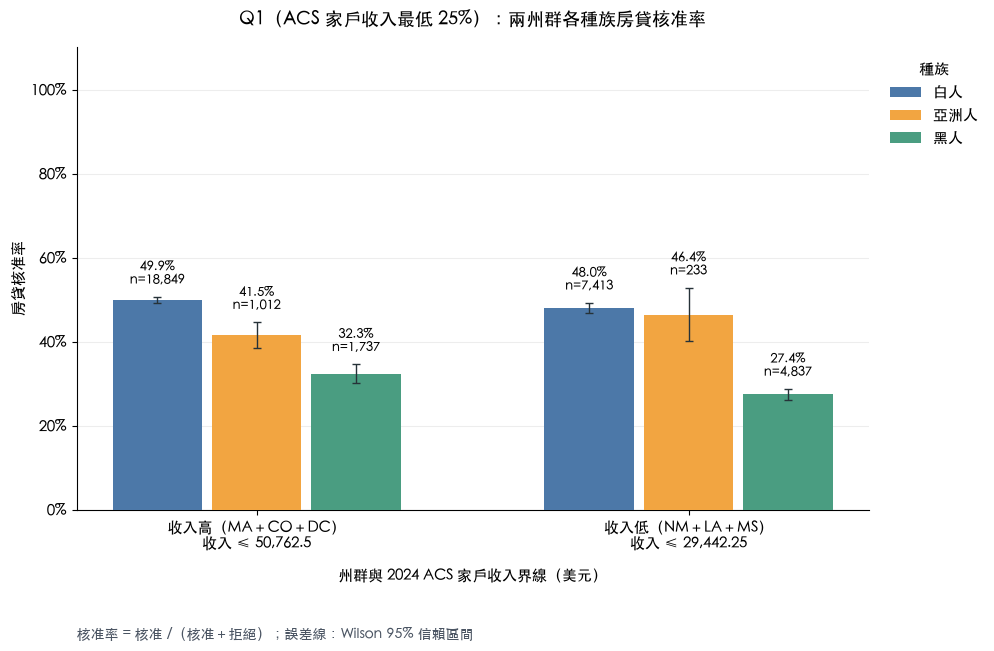

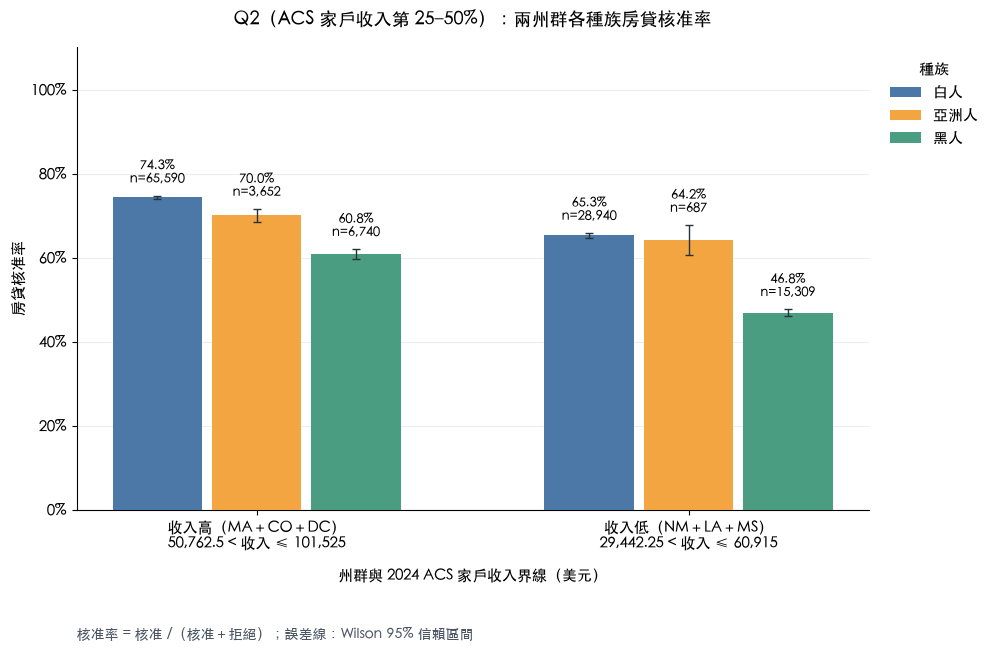

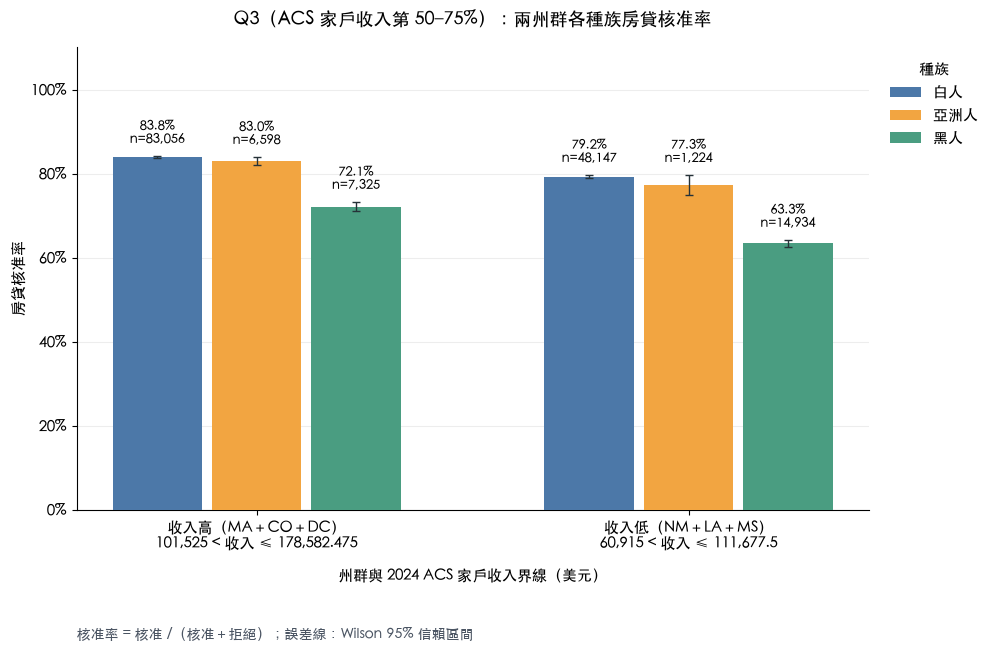

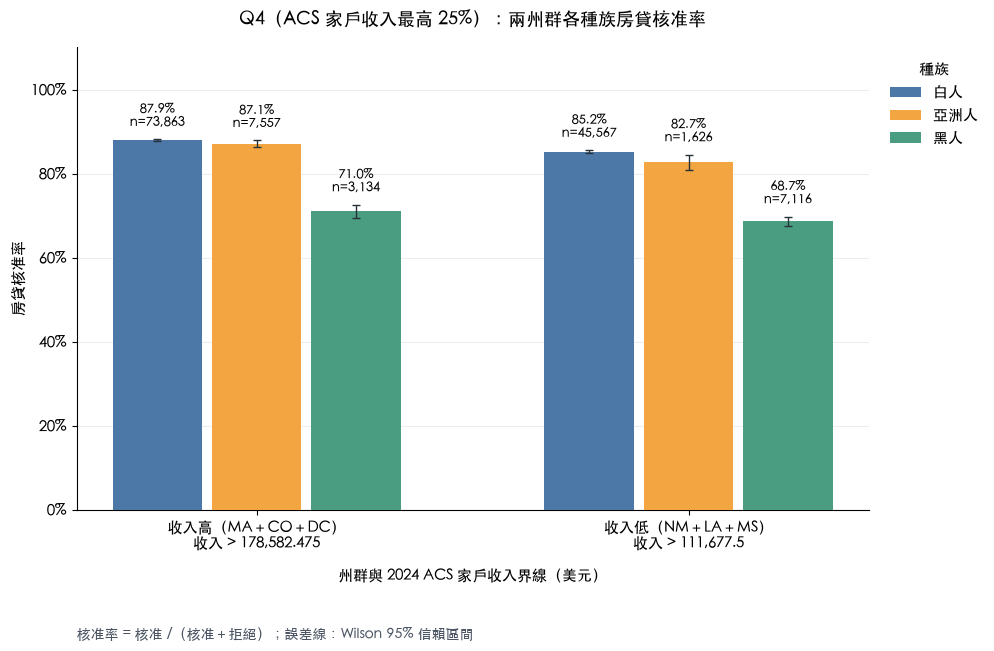

In [5]:
group_labels={groups[0]:'收入高（MA＋CO＋DC）',groups[1]:'收入低（NM＋LA＋MS）'}
colors=['#4C78A8','#F2A541','#4A9D81']
race_labels=['白人','亞洲人','黑人']
quartile_labels={'Q1':'ACS 家戶收入最低 25%','Q2':'ACS 家戶收入第 25–50%','Q3':'ACS 家戶收入第 50–75%','Q4':'ACS 家戶收入最高 25%'}
def income_range(state,q):
    a,b,c=[f'{v*1000:,.3f}'.rstrip('0').rstrip('.') for v in cutoffs.loc[state]]
    return {'Q1':f'收入 ≤ {a}', 'Q2':f'{a} < 收入 ≤ {b}', 'Q3':f'{b} < 收入 ≤ {c}', 'Q4':f'收入 > {c}'}[q]
def draw_chart(ax,q):
    width=.23
    for j,(race,label,color) in enumerate(zip(races,race_labels,colors)):
        group=summary.xs((q,race),level=('income_quartile','derived_race')).reindex(groups)
        x=np.arange(2)+(j-1)*width
        for k,row in enumerate(group.itertuples()):
            if row.n==0:
                ax.text(x[k],.025,'無樣本',ha='center',fontsize=9)
                continue
            ax.bar(x[k],row.approval_rate,width*.9,color=color,label=label if k==0 else None,zorder=3)
            ax.errorbar(x[k],row.approval_rate,yerr=[[max(0,row.approval_rate-row.ci95_low)],[max(0,row.ci95_high-row.approval_rate)]],fmt='none',ecolor='#263238',capsize=3,lw=1,zorder=4)
            ax.text(x[k],min(.99,row.ci95_high+.025),f'{row.approval_rate:.1%}\nn={row.n:,}',ha='center',va='bottom',fontsize=9)
    ax.set_title(f'{q}（{quartile_labels[q]}）：兩州群各種族房貸核准率',fontsize=13,pad=16)
    ax.set_xticks([0,1], [f'{group_labels[s]}\n{income_range(s,q)}' for s in groups])
    ax.set_xlabel('州群與 2024 ACS 家戶收入界線（美元）',labelpad=12)
    ax.set_ylabel('房貸核准率')
    ax.set_ylim(0,1.1)
    ax.set_yticks(np.arange(0,1.01,.2))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis='y',alpha=.22,zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top','right']].set_visible(False)
    ax.legend(title='種族',loc='upper left',bbox_to_anchor=(1.01,1),frameon=False)
for q in ['Q1','Q2','Q3','Q4']:
    fig,ax=plt.subplots(figsize=(11,7))
    draw_chart(ax,q)
    fig.text(.1,.025,'核准率 = 核准 /（核准＋拒絕）；誤差線：Wilson 95% 信賴區間',fontsize=10,color='#4b5563')
    fig.subplots_adjust(left=.1,right=.82,bottom=.21,top=.87)
    fig.savefig(assets/f'{q}_approval_rate.png',dpi=180,facecolor='white')
    plt.show()
    plt.close(fig)
# A combined overview supports easy comparison; the four separate files are also saved.
fig,axes=plt.subplots(2,2,figsize=(19,13))
for ax,q in zip(axes.flat,['Q1','Q2','Q3','Q4']):
    draw_chart(ax,q)
fig.subplots_adjust(left=.06,right=.92,bottom=.13,top=.93,wspace=.44,hspace=.58)
fig.text(.06,.025,'門檻：income_quartiles_by_income_group_2024.csv（2024 ACS 州群家戶收入）；核准 = action_taken 1、2；拒絕 = 3；誤差線：Wilson 95% 信賴區間',fontsize=12)
fig.savefig(assets/'all_quartiles.png',dpi=150,facecolor='white')
plt.close(fig)


兩群各以申請紀錄數加權合併，並非州核准率的簡單平均；高收入組以 CO、MA 申請數較多，低收入組以 LA、MS 較多。兩州群收入門檻不同，同一 Q1–Q4 不代表完全相同美元收入。門檻來自一般家戶，而非房貸申請人的收入分位數。房貸資料年份尚未確認，不能假定與 2024 ACS 同期。收入缺失排除可能影響組成，Wilson 區間未調整同機構或重複申請相關性。圖表未控制州別、信用或貸款條件，不推論歧視或因果效果。作者待確認。


In [6]:
for q in ['Q1','Q2','Q3','Q4']:
    lines=[]
    for race,label in zip(races,race_labels):
        high=summary.loc[(q,groups[0],race),'approval_rate']
        low=summary.loc[(q,groups[1],race),'approval_rate']
        lines.append(f'{label}：高收入組 {high:.1%}、低收入組 {low:.1%}（高−低 {(high-low)*100:+.1f} 個百分點）')
    display(Markdown(f'**{q}**：'+'；'.join(lines)+'。'))
print(f'執行完成：來源 {len(df):,} 筆；排除無效收入 {(~finite).sum():,} 筆；分析 {len(analysis):,} 筆。24 組結果已重新讀取核對；四張圖及總覽圖已儲存。')


**Q1**：白人：高收入組 49.9%、低收入組 48.0%（高−低 +1.9 個百分點）；亞洲人：高收入組 41.5%、低收入組 46.4%（高−低 -4.8 個百分點）；黑人：高收入組 32.3%、低收入組 27.4%（高−低 +4.9 個百分點）。

**Q2**：白人：高收入組 74.3%、低收入組 65.3%（高−低 +9.1 個百分點）；亞洲人：高收入組 70.0%、低收入組 64.2%（高−低 +5.9 個百分點）；黑人：高收入組 60.8%、低收入組 46.8%（高−低 +14.0 個百分點）。

**Q3**：白人：高收入組 83.8%、低收入組 79.2%（高−低 +4.6 個百分點）；亞洲人：高收入組 83.0%、低收入組 77.3%（高−低 +5.7 個百分點）；黑人：高收入組 72.1%、低收入組 63.3%（高−低 +8.8 個百分點）。

**Q4**：白人：高收入組 87.9%、低收入組 85.2%（高−低 +2.7 個百分點）；亞洲人：高收入組 87.1%、低收入組 82.7%（高−低 +4.4 個百分點）；黑人：高收入組 71.0%、低收入組 68.7%（高−低 +2.3 個百分點）。

執行完成：來源 470,123 筆；排除無效收入 14,977 筆；分析 455,146 筆。24 組結果已重新讀取核對；四張圖及總覽圖已儲存。
